# Tutorial 9 — More models: committees, the autoencoder, backbones and heads, the Python API

*Part 4 — Going further · tutorial 9 of 9 · previous: [08 Oscillator strengths](08_oscillator_strengths.ipynb)*

This tutorial collects the remaining modelling tools:

1. **committees** of models and their uncertainty (the basis of active learning);
2. the **autoencoder** model, `AutoencoderExcitedMACE`;
3. **backbones, foundation models, heads**, Stage Two and restarts (an overview;
   Tutorial 4 shows foundation models and fine-tuning in practice);
4. the **Python API** for custom training loops.

**Requirements:** the SO2 data (Tutorial 2) and model (Tutorial 3); SHARC for the
reference curve in section 1. Runtime: about 12 minutes.

In [1]:
import json
import re
import shutil
import subprocess
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import ase
import ase.io
import matplotlib.pyplot as plt
import numpy as np
import torch

import mace  # noqa: F401
from mace import modules, tools

TUTORIAL = Path.cwd()
sys.path.insert(0, str(TUTORIAL / "tools"))
import so2_lvc as lvc

WORK = TUTORIAL / "work"
plt.rcParams.update({"figure.dpi": 100})
np.set_printoptions(precision=4, suppress=True, linewidth=120)
torch.set_default_dtype(torch.float64)  # the trained models are in float64


def strip(line):
    return re.sub(r"^\d{4}-\d\d-\d\d [\d:.]+ [A-Z]+: ", "", line)


def train(name, extra, directory, epochs=10, train_file="../so2_train.xyz"):
    """A short training run in work/<directory> (same settings as Tutorial 3)."""
    run = WORK / directory
    if run.exists():
        shutil.rmtree(run)  # MACE appends to existing log files
    run.mkdir(parents=True)
    command = [
        "mace_run_train", f"--name={name}", f"--train_file={train_file}", "--valid_fraction=0.1",
        "--model=ExcitedMACE", "--states=4 0 3", "--compute_nacs", "--compute_socs", "--compute_dipoles",
        "--E0s=average", "--r_max=5.0", "--hidden_irreps=32x0e + 32x1o", "--MLP_irreps=16x0e",
        "--num_interactions=2", "--correlation=2", "--batch_size=10", f"--max_num_epochs={epochs}",
        "--lr=0.01", "--ema", "--ema_decay=0.99", "--energy_weight=10", "--forces_weight=100",
        "--nacs_weight=10", "--socs_weight=1", "--dipoles_weight=1", "--default_dtype=float64",
        "--device=cpu",
    ] + extra
    result = subprocess.run(command, cwd=run, capture_output=True, text=True)
    if result.returncode != 0:
        print(result.stdout[-3000:], result.stderr[-3000:])
        raise RuntimeError(f"training {name} failed")
    return (run / "logs" / f"{name}_run-{_seed(extra)}.log").read_text()


def _seed(extra):
    for item in extra:
        if item.startswith("--seed="):
            return item.split("=")[1]
    return "123"

## 1. Committees and uncertainty

A single model gives no idea of how much to trust a prediction. Training several
models that differ only in their random initialisation (`--seed`) gives a
**committee**: where the training data covers the geometry, the members agree;
where they extrapolate, they disagree. The spread is a cheap uncertainty estimate.

This is the core of **active learning**: run dynamics with the committee, collect
geometries where the spread is large, compute reference data there, retrain, repeat.

We train a second, quick model (20 epochs, seed 2) and combine it with the model of
Tutorial 3. A real committee would use 3–5 fully trained members.

In [2]:
log = train("so2_seed2", ["--seed=2"], "committee", epochs=20)
table = log[log.index("Error-table on TRAIN"):].splitlines()[:7]
print("\n".join(strip(line) for line in table))

Error-table on TRAIN and VALID:
+---------------+-------------+--------------------+-----------------+-------------+------------------+------------------+---------------------+
|  config_type  | MAE E / meV | MAE E / meV / atom | MAE F / meV / A | rel F MAE % | MAE NACs (x1e-3) | MAE SOCs (x1e-3) | MAE dipoles (x1e-3) |
+---------------+-------------+--------------------+-----------------+-------------+------------------+------------------+---------------------+
| train_Default |       14.1  |           4.7      |         79.9    |       3.23  |       231.48     |      3460.02     |          12.14      |
| valid_Default |       15.3  |           5.1      |        112.1    |       4.88  |       267.54     |      3996.39     |          13.44      |
+---------------+-------------+--------------------+-----------------+-------------+------------------+------------------+---------------------+


committee of 2 models


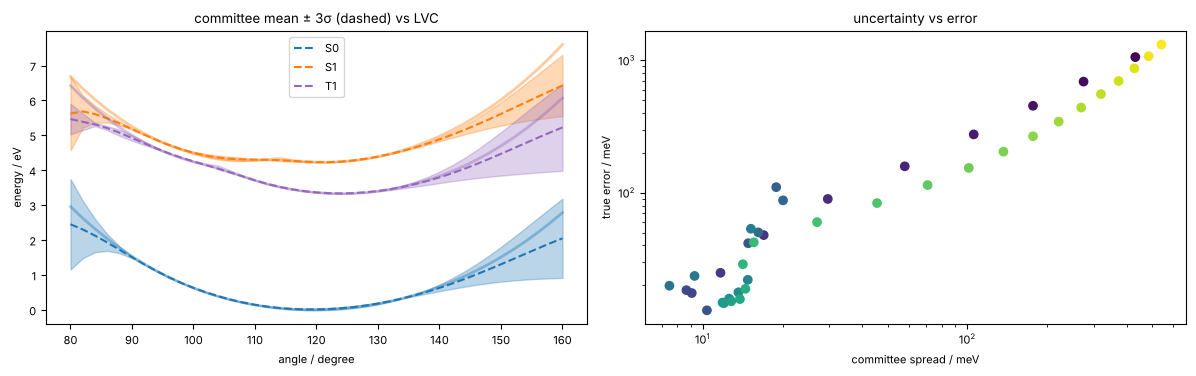

In [3]:
from mace.calculators import ExcitedMACECalculator

committee = ExcitedMACECalculator([str(WORK / "so2.model"), str(WORK / "committee" / "so2_seed2.model")], device="cpu")
print("committee of", committee.num_models, "models")

v0 = lvc.read_v0(WORK / "lvc_model" / "V0.txt")
r0 = np.linalg.norm(v0["coords"][1] - v0["coords"][0]) * lvc.BOHR_TO_ANGSTROM


def bend(angle_deg, r=r0):
    half = np.radians(angle_deg) / 2
    return np.array([[0, 0, 0], [0, -r * np.sin(half), r * np.cos(half)], [0, r * np.sin(half), r * np.cos(half)]])


angles = np.linspace(80, 160, 41)  # beyond the sampled range on both ends
positions = np.array([bend(a) for a in angles])
reference = lvc.lvc_reference(WORK / "lvc_model", positions / lvc.BOHR_TO_ANGSTROM)
ref_energies = np.array([np.diag(h).real[:7] for h in reference["h"]]) * 27.211386
predictions = [committee.predict(ase.Atoms(v0["symbols"], positions=p)) for p in positions]
mean = np.array([p["energies"] for p in predictions])
spread = np.sqrt(np.array([p["energies_var"] for p in predictions]))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for s in (0, 1, 4):
    axes[0].plot(angles, ref_energies[:, s], lw=2, alpha=0.4, color=f"C{s}")
    axes[0].fill_between(angles, mean[:, s] - 3 * spread[:, s], mean[:, s] + 3 * spread[:, s], color=f"C{s}", alpha=0.3)
    axes[0].plot(angles, mean[:, s], ls="--", color=f"C{s}", label=["S0", "S1", "", "", "T1"][s])
axes[0].set(xlabel="angle / degree", ylabel="energy / eV", title="committee mean ± 3σ (dashed) vs LVC")
axes[0].legend()
error = np.abs(mean - ref_energies).max(axis=1)
axes[1].scatter(spread.max(axis=1) * 1000, error * 1000, c=angles, cmap="viridis")
axes[1].set(xlabel="committee spread / meV", ylabel="true error / meV", title="uncertainty vs error", xscale="log", yscale="log")
plt.tight_layout()

The spread grows towards the ends of the scan, outside the training data, together
with the true error (right: one point per geometry, coloured by the bend angle). In SHARC, give a glob pattern as `model_file`
(`so2*.model`) and the committee mean drives the dynamics.

## 2. `AutoencoderExcitedMACE`

`ExcitedMACE` predicts each state's energy with its own readout. Nothing forces
state *i* to stay below state *i+1*, and near a conical intersection the two
readouts must produce the cusp of the adiabatic surfaces.

`AutoencoderExcitedMACE` predicts instead a permutation-invariant latent vector,
from which a decoder builds a symmetric tridiagonal matrix; **the energies are its
eigenvalues**. They are ordered by construction, and crossings come out of the
eigenvalue problem naturally. With several multiplicities the matrix has one block
per multiplicity, so the states are ordered **within each multiplicity**, like
SHARC's MCH states (a triplet may lie below a singlet). During training an encoder
maps the reference energies into the same latent space; the loss asks the decoder to
reconstruct them and the network to reproduce the encoded vector. Use it when states
cross often; the options are the same plus `--num_permutational_invariant` (latent
size).

In [4]:
log = train("so2_ae", ["--model=AutoencoderExcitedMACE", "--num_permutational_invariant=16", "--seed=3"], "autoencoder", epochs=10)
for line in log.splitlines():
    if "AutoencoderExcitedMACE:" in line or "Epoch 9:" in line:
        print(strip(line)[:240])
ae = ExcitedMACECalculator(str(WORK / "autoencoder" / "so2_ae.model"), device="cpu")
energies = np.array([ae.predict(ase.Atoms(v0["symbols"], positions=p))["energies"] for p in positions[:, :, :]])
# 10 epochs are far too few for a good model; this only shows how to train one
singlets_ordered = np.all(np.diff(energies[:, :4], axis=1) >= 0)
triplets_ordered = np.all(np.diff(energies[:, 4:], axis=1) >= 0)
print("singlets ordered along the scan:", bool(singlets_ordered), "| triplets ordered:", bool(triplets_ordered))

AutoencoderExcitedMACE: 7 states (4 singlets, 3 triplets), NACs=9 (raw), SOCs=15 coupling vectors (spin_orbit), dipoles=16, coupling parity=both, pair repulsion=off, backbone=ScaleShiftMACE, long range=shared
Epoch 9: head: Default, loss=8.74978700, MAE_E=  186.18 meV, MAE_E_per_atom=   62.06 meV, MAE_F=  261.38 meV / A, MAE_NACs=  343.70 (x1e-3), MAE_SOCs= 5083.02 (x1e-3), MAE_dipoles=   16.23 (x1e-3)


singlets ordered along the scan: True | triplets ordered: True


## 3. Backbones, foundation models, heads, Stage Two and restarts

* **Backbones.** Both models sit on a ground-state MACE model, the backbone:
  `--excited_backbone=ScaleShiftMACE` (default), `MACE`, `MACELES`, `PolarMACE` or
  `MagneticScaleShiftMACE`. The energy of every state is the backbone's energy plus a
  per-state correction that starts at zero, and an adapter layer with l = 1 features
  feeds the coupling readouts. With an electrostatic backbone (MACELES, PolarMACE),
  `--excited_long_range=shared` gives every state the backbone's electrostatics and
  `state` gives every state its own charges (summing to the same total charge).
* **Foundation models** (in practice: Tutorial 4). `--foundation_model=...` makes a
  foundation model the backbone: MACE-MP/MPA/OMAT/MATPES (`small`, `medium-mpa-0`, ...), MACE-OFF
  (`small_off`, ...), MACE-OMOL (`mace_omol`), MACE-MH-1 (`mh-1` with
  `--foundation_head=omol`, for example) or MACE-POLAR-1 (`polar-1-s`, ...). Every
  state starts on the foundation's ground-state surface, which helps with small data
  sets. The architecture options (`--hidden_irreps`, `--r_max`, ...) come from the
  foundation model.
* **Heads.** `--heads` takes a dictionary of data sets, each with its own number of
  states and couplings (`n_energies`, `states`, `compute_nacs`, ...) or
  `ground_state: True` for plain ground-state data. With a foundation model,
  `--multiheads_finetuning=True --pt_train_file=... --E0s=foundation` adds MACE's
  replay head (`pt_head`), so the model keeps the foundation's ground state while it
  learns the excited states. `--lora=True` trains low-rank adapters in the backbone
  instead of all its weights; the excited-state readouts stay fully trainable.
  `ExcitedMACECalculator(model, head="ground")` (and `head` in `MACE.template`)
  selects a head. `XMACE.md` has the details and complete command lines.
* **Stage Two** (`--swa --start_swa=<epoch> --swa_energy_weight=... --swa_forces_weight=...`):
  for the last epochs, a lower learning rate and different loss weights, typically a
  higher energy weight.
* **Restarts:** `--restart_latest` continues from the last checkpoint in
  `checkpoints/`.
* **float32 and GPUs:** `--default_dtype=float32 --device=cuda` trains much faster;
  evaluate in float64 if you need very smooth surfaces.

## 4. The Python API

Everything the command line does is available from Python, for custom training
loops or new kinds of data. The pieces:

* `mace.data.excited.ExcitedStateSpec` — what the model predicts;
* `standardise_excited_configs` — converts labels to the model layout (smooth NACs,
  SOC vectors, missing labels → weight 0);
* `mace.modules.ExcitedMACE` / `AutoencoderExcitedMACE` — the models;
* `mace.modules.WeightedExcitedStatesLoss` — the phase-free loss;
* `mace.modules.spin_states` — state order, selection rules, SOC matrices.

In [5]:
from mace import data
from mace.data.excited import ExcitedStateSpec, standardise_excited_configs
from mace.modules.spin_states import same_multiplicity_pairs, soc_pair_weights
from mace.tools import torch_geometric

states = [4, 0, 3]
pairs = same_multiplicity_pairs(states)
spec = ExcitedStateSpec(n_states=7, n_nacs=len(pairs), n_dipoles=7 + len(pairs), states=states, soc_mode="spin_orbit")
keyspec = data.KeySpecification(
    info_keys={"energy": "REF_energy", "socs": "REF_socs", "dipoles": "REF_dipoles"},
    arrays_keys={"forces": "REF_forces", "nacs": "REF_nacs"},
)
configs = [data.config_from_atoms(a, key_specification=keyspec) for a in ase.io.read(WORK / "so2_train.xyz", ":40")]
standardise_excited_configs(configs, spec)
z_table = tools.AtomicNumberTable([8, 16])
graphs = [data.AtomicData.from_config(c, z_table=z_table, cutoff=5.0) for c in configs]
loader = torch_geometric.dataloader.DataLoader(graphs, batch_size=10, shuffle=True)

model = torch.load(WORK / "so2.model", weights_only=False)  # continue from the trained model
weights = soc_pair_weights(states)
loss_fn = modules.WeightedExcitedStatesLoss(
    energy_weight=10.0, forces_weight=100.0, nacs_weight=10.0, socs_weight=1.0, dipoles_weight=1.0,
    n_permanent_dipoles=spec.n_permanent_dipoles, soc_pair_weights=weights / weights.mean(), soc_states=states,
)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
for step, batch in enumerate(loader):
    optimizer.zero_grad()
    output = model(batch.to_dict(), training=True, compute_force=True)
    loss = loss_fn(batch, output)
    loss.backward()
    optimizer.step()
    print(f"step {step}: loss {loss.item():.4f}, outputs: {sorted(k for k, v in output.items() if v is not None)[:6]} ...")

step 0: loss 26.3608, outputs: ['dipoles', 'displacement', 'energy', 'forces', 'ground_energy', 'nacs'] ...


step 1: loss 34.1366, outputs: ['dipoles', 'displacement', 'energy', 'forces', 'ground_energy', 'nacs'] ...


step 2: loss 51.0813, outputs: ['dipoles', 'displacement', 'energy', 'forces', 'ground_energy', 'nacs'] ...


step 3: loss 26.1008, outputs: ['dipoles', 'displacement', 'energy', 'forces', 'ground_energy', 'nacs'] ...


These are losses per batch. The validation loss in the training log is divided by
the batch size (a MACE convention), so it is about ten times smaller for
`--batch_size=10`.

## Where to go from here

* `XMACE.md` in the repository root describes every option and the data format.
* `tests/` contains small, readable examples of every feature (`test_excited_*.py`).
* For a new molecule: generate reference data with your quantum-chemistry method
  through SHARC (Tutorial 2), check the SOC residual, train or fine-tune a foundation
  model (Tutorials 3–4), validate along scans and against a few reference
  trajectories (Tutorials 5–6), and improve the data where a committee disagrees.